# 03. Dense Neural Network Experiments
**Objective:** Implement, train, and evaluate a Dense Neural Network for binary sentiment classification using the GoEmotions dataset.# 03 Dense RNN LSTM - To be implemented

In [1]:
import sys
import os
import torch
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from torch.utils.data import DataLoader, TensorDataset

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

from src.models import DenseNN
from src.train import train_model
from src.evaluate import evaluate_model, print_metrics
from src.visualize import plot_training_curves, plot_confusion_matrix

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cpu


In [2]:
train_df = pd.read_csv('../data/processed/train.csv')
test_df = pd.read_csv('../data/processed/test.csv')
label_map = {'negative': 0, 'positive': 1}
train_df['label'] = train_df['sentiment'].map(label_map)
test_df['label'] = test_df['sentiment'].map(label_map)

print(f"Train size: {len(train_df)}, Test size: {len(test_df)}")
print("\nClass distribution in Train:")
print(train_df['label'].value_counts())

Train size: 800, Test size: 200

Class distribution in Train:
label
1    400
0    400
Name: count, dtype: int64


In [3]:
#convert text to fixed-size vectors
vectorizer = CountVectorizer(max_features=5000, stop_words='english')

X_train_bow = vectorizer.fit_transform(train_df['cleaned_text']).toarray()
X_test_bow = vectorizer.transform(test_df['cleaned_text']).toarray()
y_train = train_df['label'].values
y_test = test_df['label'].values

input_dim = X_train_bow.shape[1]
print(f"Input dimension (Vocabulary size): {input_dim}")

Input dimension (Vocabulary size): 2253


In [4]:
X_train_tensor = torch.FloatTensor(X_train_bow)
y_train_tensor = torch.FloatTensor(y_train)
X_test_tensor = torch.FloatTensor(X_test_bow)
y_test_tensor = torch.FloatTensor(y_test)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

C:\Users\Krystal\AppData\Local\Temp\ipykernel_17044\3309958125.py:2: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  y_train_tensor = torch.FloatTensor(y_train)


In [5]:
from torch.utils.data import Dataset

class SentimentDataset(Dataset):

    def __init__(self, features: np.ndarray, labels: np.ndarray):
        self.features = torch.FloatTensor(features.copy())
        self.labels = torch.FloatTensor(labels.copy())

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        return {
            "input_ids": self.features[idx],
            "labels": self.labels[idx]
        }

train_dataset = SentimentDataset(X_train_bow, y_train)
test_dataset = SentimentDataset(X_test_bow, y_test)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print("DataLoaders created successfully!!!")

DataLoaders created successfully!!!


In [6]:
model_dense = DenseNN(
    input_dim=input_dim,
    hidden_dims=[256, 128],
    output_dim=1,
    dropout_rate=0.3
).to(device)

print("Training...")
history_dense = train_model(
    model=model_dense,
    train_loader=train_loader,
    val_loader=test_loader,
    epochs=20,
    lr=0.001,
    patience=4,
    device=device
)
print(" training completed!!")

Training...
 training completed!!


In [7]:
metrics_dense = evaluate_model(model_dense, test_loader, device=device)
print_metrics(metrics_dense, model_name="DenseNN (BoW)")


 Evaluation Metrics - DenseNN (BoW)
  Accuracy : 0.7200
  Precision: 0.7037
  Recall   : 0.7600
  F1-score : 0.7308
  Kappa    : 0.4400
  Confusion Matrix:
    [68, 32]
    [24, 76]



Figure saved to: ../outputs/figures/dense_training_curves.png


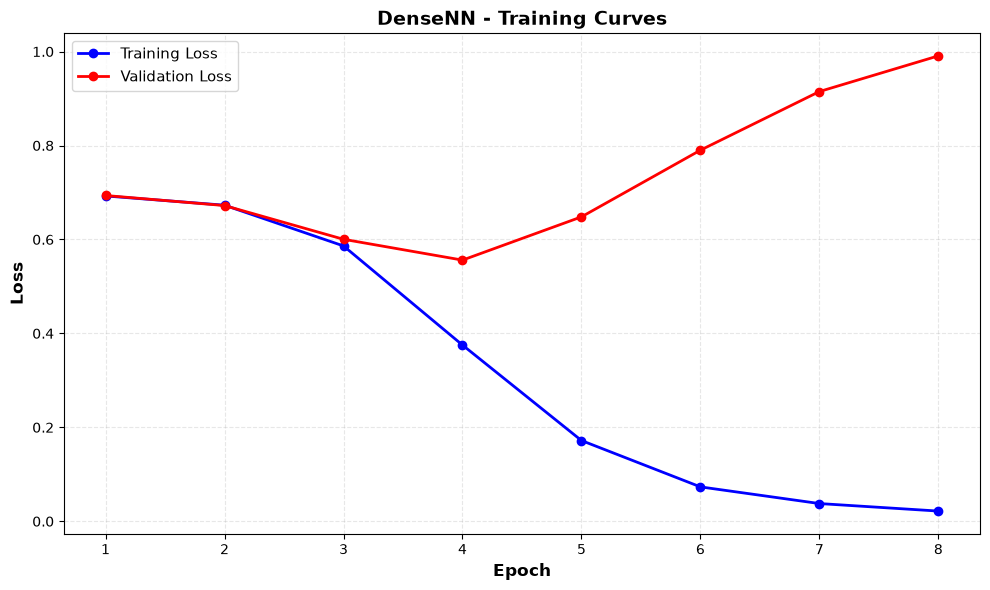

Figure saved to: ../outputs/figures/dense_confusion_matrix.png


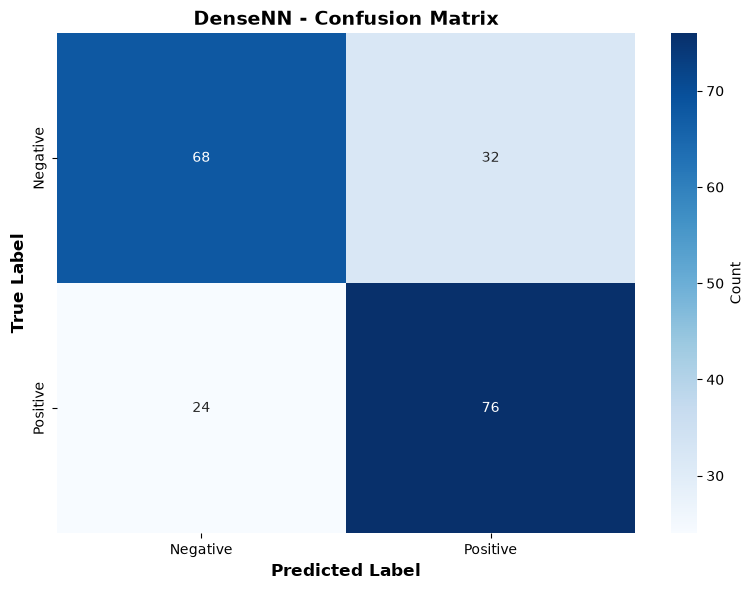

In [8]:
#save training curves
plot_training_curves(
    train_losses=history_dense['train_losses'],
    val_losses=history_dense['val_losses'],
    model_name="DenseNN",
    save_path="../outputs/figures/dense_training_curves.png",
    show=True
)

#save confusion matrix
plot_confusion_matrix(
    confusion_matrix=np.array(metrics_dense['confusion_matrix']),
    class_names=["Negative", "Positive"],
    model_name="DenseNN",
    save_path="../outputs/figures/dense_confusion_matrix.png",
    show=True
)